# Reddit: from the raw archive to daily counts

This notebook follows the Reddit data through the five steps of the pipeline (`pipeline/01_extract_reddit.py` to `pipeline/05_daily_counts.py`), with the counts of the stored outputs and hand-made examples of every rule. The notebook runs on the outputs in `data/pipeline/` and reads only stats files and aggregate counts. Every example text is hand-made; no real post, post id or account id is shown. Run it from `code/notebooks/` after the pipeline has run.

In [1]:
%matplotlib inline
import importlib
import json
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

CODE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(CODE))
from pipeline import config, rules as R  # noqa: E402

OUT = config.OUT_DIR          # data/pipeline/ (never printed: it is a local path)
con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
R.register_udfs(con)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


def stats(*parts):
    """A stats file of the pipeline, by its path under data/pipeline/."""
    return json.loads(OUT.joinpath(*parts).read_text())


def src(*parts):
    """SQL source for Parquet files under data/pipeline/ (glob patterns allowed)."""
    return f"read_parquet('{OUT.joinpath(*parts)}', hive_partitioning = false)"


def q(sql):
    return con.execute(sql).df()


def annotate(texts, own=None):
    """Hand-made texts through the computed columns of step 2 (rules.annotate_sql).
    Evidence reads `text` (the full text), structure reads `own` (the author's own words)."""
    own = own or texts
    rows = ", ".join(f"({i}, {R.dq(t)}, {R.dq(o)})" for i, (t, o) in enumerate(zip(texts, own)))
    con.execute(f"CREATE OR REPLACE TEMP TABLE hand_made AS SELECT * FROM (VALUES {rows}) v(i, text, own)")
    con.execute("CREATE OR REPLACE TEMP TABLE annotated AS " +
                R.annotate_sql("SELECT i, text, own FROM hand_made", "text", "own") + " ORDER BY i")
    return q("SELECT * FROM annotated ORDER BY i")


def gates(extra=""):
    """The coin gate (rules.coin_gate) and the market rule on the last annotated examples."""
    coins = ", ".join(f"{R.coin_gate(c)} AS {c.lower()}" for c in R.COINS)
    any_coin = " OR ".join(R.coin_gate(c) for c in R.COINS)
    return q(f"SELECT text, {coins}, {R.market_rule(any_coin)} AS market{extra} FROM annotated ORDER BY i")


def daily_summary(platform):
    """Posts per UTC day after the bot filter, per series (step 5)."""
    d = q(f"""SELECT series, CAST(count(*) AS BIGINT) AS days, CAST(sum(n_posts) AS BIGINT) AS posts,
                     round(avg(n_posts), 1) AS mean_per_day, median(n_posts) AS median_per_day,
                     CAST(min(n_posts) AS BIGINT) AS min_per_day, CAST(max(n_posts) AS BIGINT) AS max_per_day,
                     CAST(count_if(n_posts = 0) AS BIGINT) AS days_without_posts
              FROM {src('panel', 'daily_counts.parquet')} WHERE platform = '{platform}' GROUP BY 1""")
    order = ["BTC", "ETH", "BNB", "XRP", "DOGE", "MARKET", "CRYPTO_SET"]
    d["k"] = [order.index(s) if s in order else 99 for s in d.series]
    return d.sort_values(["k", "series"]).drop(columns="k").set_index("series")


def weekly_plot(platform, title):
    # Twitter: a day without any capture is missing, not a day without posts (its count is 0 in the table;
    # how the attention variable treats such days is decision D14). Those days are left out of the weekly
    # mean, so a week without any capture shows as a gap in the line.
    keep = "TRUE" if platform != "twitter" else (
        f"day IN (SELECT utc_day FROM {src('twitter', 'units', 'twitter_coverage_utc.parquet')} WHERE minutes_utc > 0)")
    w = q(f"""SELECT series, date_trunc('week', day) AS week, avg(n_posts) FILTER (WHERE {keep}) AS posts_per_day
              FROM {src('panel', 'daily_counts.parquet')}
              WHERE platform = '{platform}' AND series IN ('BTC', 'ETH', 'BNB', 'XRP', 'DOGE', 'MARKET')
              GROUP BY 1, 2 ORDER BY 2""")
    fig, ax = plt.subplots(figsize=(9, 4))
    for s in ["BTC", "ETH", "BNB", "XRP", "DOGE", "MARKET"]:
        x = w[w.series == s]
        ax.plot(x.week, x.posts_per_day, label=s, linewidth=1)
    ax.set_yscale("log")
    ax.set_ylabel("posts per day (weekly mean, log scale)")
    ax.set_title(title)
    ax.legend(ncol=6, fontsize=8, frameon=False)
    fig.tight_layout()
    return fig


## Step 1: extract (`01_extract_reddit.py`)

The Arctic Shift dumps of the 14 study subreddits are checked object by object (md5 against the manifest, `gzip -t`), parsed line by line (every line is accounted for), restricted to the window 1 Aug 2019 – 31 Jan 2023 (UTC), and reduced to one row per post id. The subreddits form six groups:

| Group | Subreddits |
|---|---|
| BTC | r/bitcoin, r/btc, r/bitcoinmarkets |
| ETH | r/ethereum, r/ethtrader, r/ethfinance |
| BNB | r/binance |
| XRP | r/xrp, r/ripple |
| DOGE | r/dogecoin |
| MARKET | r/cryptocurrency, r/cryptomarkets, r/satoshistreetbets, r/cryptocurrencytrading |

Removed and deleted rows are kept as dead rows (text empty, `is_dead`); they never enter a series, but the daily counts report them. Authors are stored only as a salted hash.

In [2]:
groups = ["BTC", "ETH", "BNB", "XRP", "DOGE", "MARKET"]
rows = []
for g in groups:
    e = stats("reddit", "extract", f"reddit_{g}_stats.json")
    c = stats("reddit", "coarse", f"coin={g}", "_stats.json")["counts"]
    rows.append({"group": g, "lines read": e["counts"]["lines"], "in the window": e["counts"]["kept"],
                 "one row per id": c["rows"], "live": c["live"], "dead": c["dead"]})
extract = pd.DataFrame(rows).set_index("group")
extract.loc["all"] = extract.sum()
extract

,lines read,in the window,one row per id,live,dead
group,,,,,
BTC,8017413,8017413,7987280,6989144,998136
ETH,4858697,4858697,4856461,4086014,770447
BNB,940072,940072,940072,608503,331569
XRP,616875,616875,616721,465794,150927
DOGE,9319024,9319024,9160745,7889420,1271325
MARKET,31494496,31494496,31446479,27011514,4434965
all,55246577,55246577,55007758,47050389,7957369


The difference between *in the window* and *one row per id* is the posts that appear in more than one dump file; the copy kept is fixed by source file, then latest retrieval, then line number.

## Step 2: computed columns (`02_filter_reddit.py`)

Reddit needs no inclusion filter: every row is kept, because the subreddit already says what a post is about. Step 2 adds the columns every platform gets from `rules.py`:

* **evidence** (which coins and which crypto context a post names) on the full text, quote lines included;
* **structure** (length, links, hashtags, mentions, cashtags, `is_url_only`, the fingerprint used by the campaign rule) on the author's own words, quote lines removed.

Before matching, the text is HTML-decoded, links are removed (a coin word inside a URL does not count; `coin_only_in_link` marks posts whose only coin word is in a link), and cashtags are masked for tier-2 and tier-3 words. The stored text is never changed.

Hand-made examples (the first has a quote line, so its own words differ from its full text):

In [3]:
texts = ["> bitcoin is dead\nNo, BTC will recover", "Buy ETH now https://example.com/bitcoin",
         "read this https://example.com/bitcoin-news", "@someone https://example.com/x",
         "I bought some doge today, crypto is fun"]
own = ["No, BTC will recover", texts[1], texts[2], texts[3], texts[4]]
ex = annotate(texts, own)
ex[["text", "hit_btc_t1", "hit_btc_t2", "hit_eth_t1", "hit_eth_t3", "hit_doge_t3", "ctx_crypto", "coin_only_in_link",
    "n_urls", "n_mentions", "is_url_only", "n_tokens"]]

,text,hit_btc_t1,hit_btc_t2,hit_eth_t1,hit_eth_t3,hit_doge_t3,ctx_crypto,coin_only_in_link,n_urls,n_mentions,is_url_only,n_tokens
0,"> bitcoin is dead\nNo, BTC will recover",True,True,False,False,False,False,False,0,0,False,4
1,Buy ETH now https://example.com/bitcoin,False,False,False,True,False,False,False,1,0,False,4
2,read this https://example.com/bitcoin-news,False,False,False,False,False,False,True,1,0,False,3
3,@someone https://example.com/x,False,False,False,False,False,False,False,1,1,True,2
4,"I bought some doge today, crypto is fun",False,False,False,False,True,True,False,0,0,False,8


Counts on the live rows of each group (tier 1 and 2 of the group's own coin; `bch_mention` and `btc_ticker` serve the r/btc rule of step 4):

In [4]:
rows = []
for g in groups:
    c = stats("reddit", "coarse", f"coin={g}", "_stats.json")["counts"]
    ev = c["evidence_live"]
    own_coin = g.lower() if g != "MARKET" else None
    rows.append({"group": g, "live rows": c["live"],
                 "own coin tier 1": ev.get(f"hit_{own_coin}_t1") if own_coin else None,
                 "own coin tier 2": ev.get(f"hit_{own_coin}_t2") if own_coin else None,
                 "crypto context": ev["ctx_crypto"], "coin word only in a link": ev["coin_only_in_link"],
                 "link only (is_url_only)": ev["url_only"], "bch_mention": c["bch_mention_live"],
                 "btc_ticker": c["btc_ticker_live"]})
pd.DataFrame(rows).set_index("group").astype("Int64")

,live rows,own coin tier 1,own coin tier 2,crypto context,coin word only in a link,link only (is_url_only),bch_mention,btc_ticker
group,,,,,,,,
BTC,6989144,1269755,564342,738665,58459,31665,236961,556086
ETH,4086014,259289,27777,562676,13614,13758,5431,114051
BNB,608503,1496,26299,187007,7224,2666,592,17065
XRP,465794,125956,733,59893,2340,2008,365,11743
DOGE,7889420,425260,0,714942,41578,25464,2777,77378
MARKET,27011514,<NA>,<NA>,4548033,28426,38674,63701,1040577


## Step 3: bot filter (`03_bot_filter.py`)

Every rule runs on all posts and writes its own flag; no rule runs only on what another rule left. A post flagged by any rule except the invite-link rule (`bot_any`) leaves the main series in step 4. Every rule looks only at data up to the post's own UTC day (an account's window is its 200 most recent posts up to that day).

| Rule | On Reddit | Source |
|---|---|---|
| automod | the author is AutoModerator | arXiv 2601.14423 |
| self_id | the own text says "performed automatically" or "i am a bot" | Yang et al. (2020) |
| name | "bot" is a separate token of the user name | arXiv 2601.14423 |
| keyword | at least 2 of: give-away words; pump with join/register; > 5 hashtags; > 5 crypto tickers; "bot" in the name | Kraaijeveld & De Smedt (2020), Electronic Markets (2025) |
| campaign | a fingerprint posted by >= 20 accounts on one UTC day forms a group; a member account is a bot that day if >= 60% of its window carry fingerprints found in the windows of >= 3 of the group's accounts | Chen & Subramanian (2018) |
| template | more than half of the pairs in an account's window are near-copies (difflib ratio > 0.7) | Electronic Markets (2025) |
| invite | Telegram/Discord invite link: flag only, never in `bot_any` | Nizzoli et al. (2020) |

In [5]:
f = stats("reddit", "bot", "post_flags.parquet.stats.json")["counts"]
rules = pd.DataFrame({"posts flagged": f["flags"], "flagged by this rule only": f.get("flag_only_this_rule", {})}).astype("Int64")
rules.index.name = "rule"
print(f"{f['posts']:,} posts; campaign groups: {f['campaign']['groups']:,}; "
      f"template bot account-days: {f['template']['bot_account_days']:,} of {f['template']['account_days']:,}")
rules

47,050,389 posts; campaign groups: 841; template bot account-days: 88,961 of 13,458,083


,posts flagged,flagged by this rule only
rule,,
bot_keyword,658,222
bot_campaign,13652,10284
bot_template,511178,445206
bot_automod,747568,6983
bot_self_id,833431,59662
bot_name,194532,166500
invite_link,52738,<NA>
bot_any,1486148,<NA>


## Step 4: series (`04_series_reddit.py`)

On Reddit a post counts for its subreddit's coin. Two subreddits need a rule: in r/btc, posts about Bitcoin Cash and their threads are out and the rest counts only when it names a BTC ticker; in r/binance, only posts naming BNB count for BNB, posts naming another coin or crypto context go to the market series, and the rest are support posts in no series. The MARKET group is the market series. A post never counts for a coin of another subreddit, and dead rows never count.

In [6]:
a = stats("reddit", "panel", "assignment.parquet.stats.json")["counts"]
fc, after = a["flag_counts"], a["series_after_bot_pass"]
series = pd.DataFrame({"posts in the series": {s: fc[f"in_{s}"] for s in after},
                       "after the bot filter": after})
series["removed by the bot filter"] = series["posts in the series"] - series["after the bot filter"]
series.index = [s.upper() for s in series.index]
series
print(f"r/btc Bitcoin Cash posts and threads: {fc['rbtc_bitcoin_cash']:,}; r/btc without a BTC ticker: "
      f"{fc['rbtc_no_ticker']:,}; r/binance support posts: {fc['rbinance_support']:,}")

r/btc Bitcoin Cash posts and threads: 512,390; r/btc without a BTC ticker: 471,193; r/binance support posts: 389,412


## Step 5: daily counts (`05_daily_counts.py`)

Posts per series and UTC day after the bot filter, on the full 1,280-day calendar. `CRYPTO_SET` counts a post once if it is in any of the six series.

In [7]:
daily_summary("reddit")

,days,posts,mean_per_day,median_per_day,min_per_day,max_per_day,days_without_posts
series,,,,,,,
BTC,1280,5938849,4639.7,3810.5,1313,31094,0
ETH,1280,3946468,3083.2,2033.0,396,20136,0
BNB,1280,25904,20.2,7.0,0,628,104
XRP,1280,457629,357.5,184.0,19,13348,0
DOGE,1280,7774155,6073.6,706.0,19,285352,0
MARKET,1280,26071288,20368.2,12621.0,810,127894,0
CRYPTO_SET,1280,44214293,34542.4,19561.0,3145,407939,0


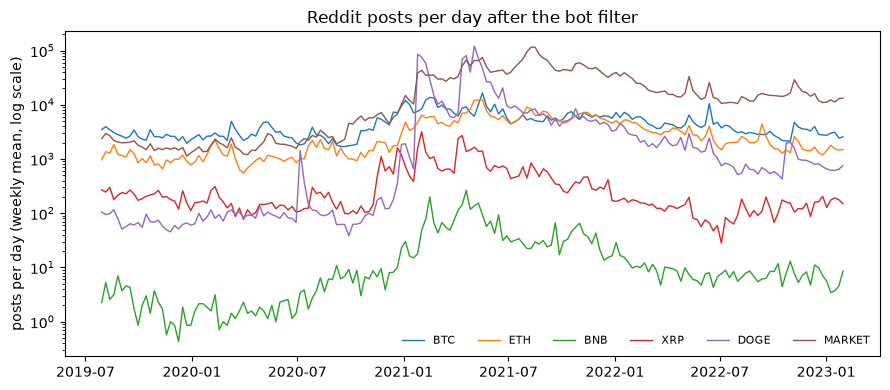

In [8]:
fig = weekly_plot("reddit", "Reddit posts per day after the bot filter")

Dead rows per group and day (`n_dead`): robustness A24 adds them to the posts before the bot filter, as a measure of total activity. They are counted per group, not per series (a dead row has no text to decide a coin).

In [9]:
q(f"""SELECT series AS group_name, CAST(sum(n_dead) AS BIGINT) AS dead_rows, round(avg(n_dead), 1) AS dead_per_day
     FROM {src('panel', 'daily_counts.parquet')}
     WHERE platform = 'reddit' AND series IN ('BTC', 'ETH', 'BNB', 'XRP', 'DOGE', 'MARKET') GROUP BY 1 ORDER BY 1""")

,group_name,dead_rows,dead_per_day
0,BNB,331569,259.0
1,BTC,998136,779.8
2,DOGE,1271325,993.2
3,ETH,770447,601.9
4,MARKET,4434965,3464.8
5,XRP,150927,117.9
